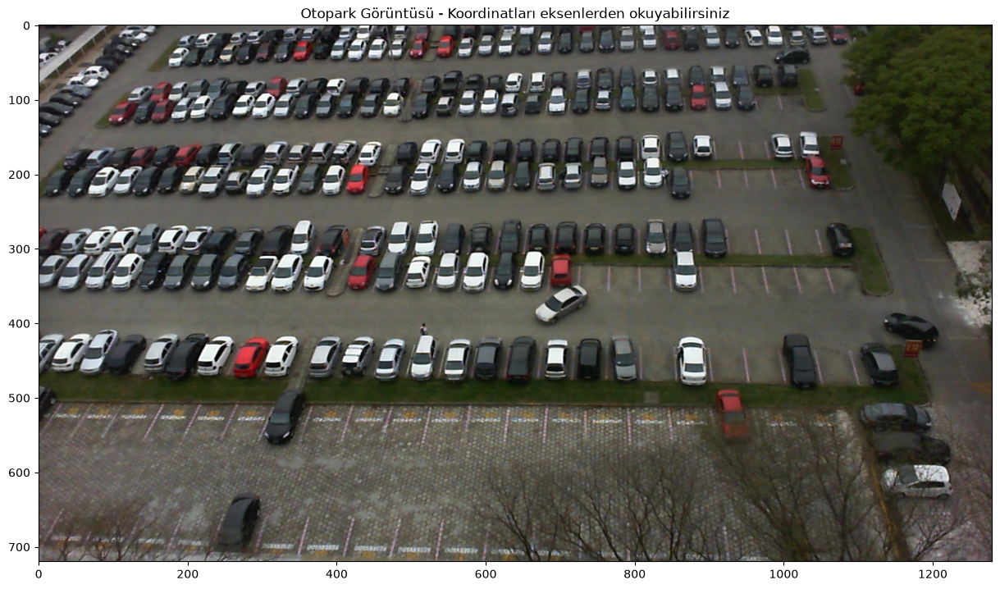

In [30]:
import cv2
import matplotlib.pyplot as plt

# 1. Resmi oku (Jupyter'in bulunduğu klasörden bir üstteki data klasörüne gidiyoruz)
resim_yolu = "../data/gelistirme/2012-09-12_07_39_15.jpg"
resim = cv2.imread(resim_yolu)

if resim is None:
    print("Hata: Fotoğraf bulunamadı. Lütfen dosya adını kontrol edin.")
else:
    # 2. OpenCV resmi BGR okur, Matplotlib ise RGB gösterir. Renkleri düzeltelim:
    resim_rgb = cv2.cvtColor(resim, cv2.COLOR_BGR2RGB)
    
    # 3. Resmi hücrenin içinde büyük ve eksenleriyle (koordinatlarıyla) birlikte göster
    plt.figure(figsize=(15, 10)) # Boyutu büyüterek pikselleri netleştirdik
    plt.imshow(resim_rgb)
    plt.title("Otopark Görüntüsü - Koordinatları eksenlerden okuyabilirsiniz")
    plt.show()

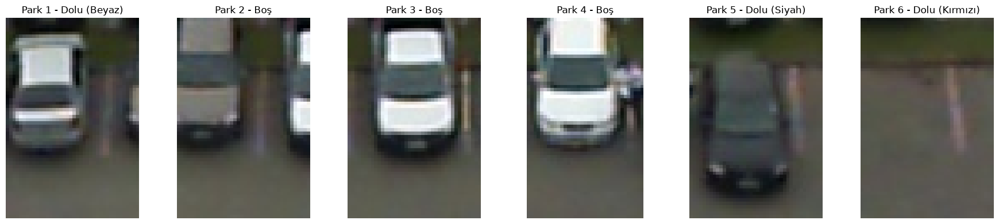

In [32]:
# Senin tespitlerine göre perspektif düzeltmesi yapılmış özel koordinatlar
park_yerleri = [
    {"id": 1, "koordinat": (705, 180, 745, 240), "durum": "Dolu (Beyaz)"},   # Sağa kaydırıldı, beyaz arabayı tam alacak
    {"id": 2, "koordinat": (745, 180, 785, 240), "durum": "Boş"},            # Beyaz arabanın bittiği yerden başlıyor
    {"id": 3, "koordinat": (770, 180, 810, 240), "durum": "Boş"},
    {"id": 4, "koordinat": (810, 180, 845, 240), "durum": "Boş"},
    {"id": 5, "koordinat": (845, 180, 885, 240), "durum": "Dolu (Siyah)"},   # Siyah araba tam ortalandı
    {"id": 6, "koordinat": (885, 180, 925, 240), "durum": "Dolu (Kırmızı)"}  # Kırmızı araba tam ortalandı
]

plt.figure(figsize=(18, 4)) 

for i, park in enumerate(park_yerleri):
    x1, y1, x2, y2 = park["koordinat"]
    kirpilmis_park = resim_rgb[y1:y2, x1:x2]
    
    plt.subplot(1, 6, i+1)
    plt.imshow(kirpilmis_park)
    plt.title(f"Park {park['id']} - {park['durum']}")
    plt.axis('off')

plt.tight_layout()
plt.show()

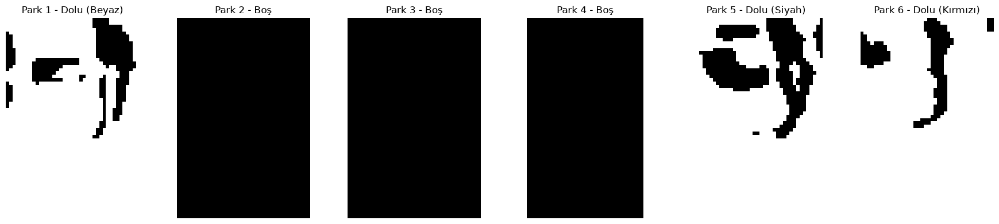

In [12]:
plt.figure(figsize=(18, 4))

for i, park in enumerate(park_yerleri):
    x1, y1, x2, y2 = park["koordinat"]
    kirpilmis_park = resim_rgb[y1:y2, x1:x2]
    
    # 1. Adım: Resmi renkli (RGB) formattan Gri Tonlamaya (Grayscale) çevir
    gri_park = cv2.cvtColor(kirpilmis_park, cv2.COLOR_RGB2GRAY)
    
    # 2. Adım: Asfalttaki pürüzleri ve ufak gölgeleri yoksaymak için Bulanıklaştırma (Blur) uygula
    blur_park = cv2.GaussianBlur(gri_park, (5, 5), 0)
    
    # 3. Adım: Eşikleme (Thresholding)
    # Parlaklık değeri 100'ün üzerinde olan pikselleri tam BEYAZ (255), altındakileri tam SİYAH (0) yap
    _, threshold_park = cv2.threshold(blur_park, 100, 255, cv2.THRESH_BINARY)
    
    plt.subplot(1, 6, i+1)
    # Matplotlib'in siyah-beyaz resmi doğru renk haritasıyla (cmap='gray') göstermesi gerekir
    plt.imshow(threshold_park, cmap='gray')
    plt.title(f"Park {park['id']} - {park['durum']}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [15]:
for i, park in enumerate(park_yerleri):
    x1, y1, x2, y2 = park["koordinat"]
    kirpilmis_park = resim_rgb[y1:y2, x1:x2]
    
    # Aynı işlemleri tekrar uyguluyoruz
    gri_park = cv2.cvtColor(kirpilmis_park, cv2.COLOR_RGB2GRAY)
    blur_park = cv2.GaussianBlur(gri_park, (5, 5), 0)
    
    # THRESH_BINARY_INV ile parlak asfaltı siyah(0), koyu renkli araç ve gölgeleri beyaz(255) yapıyoruz
    _, threshold_park = cv2.threshold(blur_park, 100, 255, cv2.THRESH_BINARY_INV)
    
    # Beyaz (sıfır olmayan) pikselleri say
    beyaz_piksel_sayisi = cv2.countNonZero(threshold_park)
    toplam_piksel = threshold_park.shape[0] * threshold_park.shape[1]
    yuzde = (beyaz_piksel_sayisi / toplam_piksel) * 100
    
    print(f"Park {park['id']} ({park['durum']}): {beyaz_piksel_sayisi} beyaz piksel (Doluluk: %{yuzde:.1f})")

Park 1 (Dolu (Beyaz)): 326 beyaz piksel (Doluluk: %13.6)
Park 2 (Boş): 0 beyaz piksel (Doluluk: %0.0)
Park 3 (Boş): 0 beyaz piksel (Doluluk: %0.0)
Park 4 (Boş): 0 beyaz piksel (Doluluk: %0.0)
Park 5 (Dolu (Siyah)): 507 beyaz piksel (Doluluk: %21.1)
Park 6 (Dolu (Kırmızı)): 220 beyaz piksel (Doluluk: %9.2)


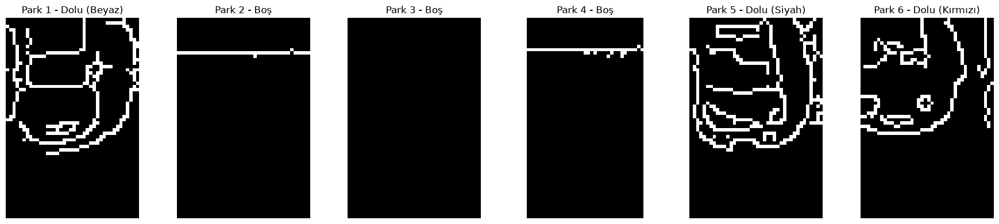

In [16]:
plt.figure(figsize=(18, 4))

for i, park in enumerate(park_yerleri):
    x1, y1, x2, y2 = park["koordinat"]
    kirpilmis_park = resim_rgb[y1:y2, x1:x2]
    
    # 1. Gri tonlamaya çevir ve bulanıklaştır (Standart ön işlemler)
    gri_park = cv2.cvtColor(kirpilmis_park, cv2.COLOR_RGB2GRAY)
    blur_park = cv2.GaussianBlur(gri_park, (5, 5), 0)
    
    # 2. Canny Kenar Belirleme (Edge Detection)
    # Alt eşik 50, üst eşik 150. Sadece belirgin kenarları (arabaların hatlarını) çizecek.
    canny_park = cv2.Canny(blur_park, 50, 150)
    
    plt.subplot(1, 6, i+1)
    plt.imshow(canny_park, cmap='gray')
    plt.title(f"Park {park['id']} - {park['durum']}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [34]:
for i, park in enumerate(park_yerleri):
    x1, y1, x2, y2 = park["koordinat"]
    kirpilmis_park = resim_rgb[y1:y2, x1:x2]
    
    # 1. Ön işlemler
    gri_park = cv2.cvtColor(kirpilmis_park, cv2.COLOR_RGB2GRAY)
    blur_park = cv2.GaussianBlur(gri_park, (5, 5), 0)
    
    # 2. Canny Edge Detection
    canny_park = cv2.Canny(blur_park, 50, 150)
    
    # 3. Kenar (beyaz) pikselleri say
    beyaz_piksel_sayisi = cv2.countNonZero(canny_park)
    toplam_piksel = canny_park.shape[0] * canny_park.shape[1]
    yuzde = (beyaz_piksel_sayisi / toplam_piksel) * 100
    
    print(f"Park {park['id']} ({park['durum']}): {beyaz_piksel_sayisi} kenar pikseli (Yoğunluk: %{yuzde:.1f})")

Park 1 (Dolu (Beyaz)): 171 kenar pikseli (Yoğunluk: %7.1)
Park 2 (Boş): 122 kenar pikseli (Yoğunluk: %5.1)
Park 3 (Boş): 208 kenar pikseli (Yoğunluk: %8.7)
Park 4 (Boş): 243 kenar pikseli (Yoğunluk: %11.6)
Park 5 (Dolu (Siyah)): 72 kenar pikseli (Yoğunluk: %3.0)
Park 6 (Dolu (Kırmızı)): 0 kenar pikseli (Yoğunluk: %0.0)


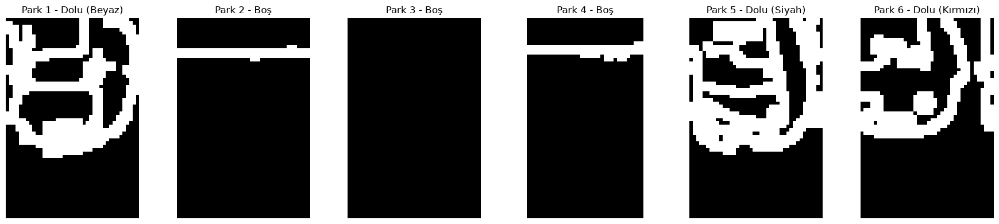

In [18]:
import numpy as np

plt.figure(figsize=(18, 4))

# Morfolojik işlemler için 3x3 boyutunda bir matris (kernel/çekirdek) oluşturuyoruz
kernel = np.ones((3, 3), np.uint8)

for i, park in enumerate(park_yerleri):
    x1, y1, x2, y2 = park["koordinat"]
    kirpilmis_park = resim_rgb[y1:y2, x1:x2]
    
    # 1. Ön işlemler ve Canny
    gri_park = cv2.cvtColor(kirpilmis_park, cv2.COLOR_RGB2GRAY)
    blur_park = cv2.GaussianBlur(gri_park, (5, 5), 0)
    canny_park = cv2.Canny(blur_park, 50, 150)
    
    # 2. Morfolojik Filtre: Dilation (Yayma)
    # iterations=1 parametresi ile beyaz çizgileri 1 kat kalınlaştırıyoruz
    morfoloji_park = cv2.dilate(canny_park, kernel, iterations=1)
    
    plt.subplot(1, 6, i+1)
    plt.imshow(morfoloji_park, cmap='gray')
    plt.title(f"Park {park['id']} - {park['durum']}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [33]:
for i, park in enumerate(park_yerleri):
    x1, y1, x2, y2 = park["koordinat"]
    kirpilmis_park = resim_rgb[y1:y2, x1:x2]
    
    # 1. Ön işlemler ve Canny
    gri_park = cv2.cvtColor(kirpilmis_park, cv2.COLOR_RGB2GRAY)
    blur_park = cv2.GaussianBlur(gri_park, (5, 5), 0)
    canny_park = cv2.Canny(blur_park, 50, 150)
    
    # 2. Morfolojik Filtre: Dilation
    morfoloji_park = cv2.dilate(canny_park, kernel, iterations=1)
    
    # 3. Yeni kalınlaşmış pikselleri say
    beyaz_piksel_sayisi = cv2.countNonZero(morfoloji_park)
    toplam_piksel = morfoloji_park.shape[0] * morfoloji_park.shape[1]
    yuzde = (beyaz_piksel_sayisi / toplam_piksel) * 100
    
    print(f"Park {park['id']} ({park['durum']}): {beyaz_piksel_sayisi} piksel (Yoğunluk: %{yuzde:.1f})")

Park 1 (Dolu (Beyaz)): 558 piksel (Yoğunluk: %23.2)
Park 2 (Boş): 380 piksel (Yoğunluk: %15.8)
Park 3 (Boş): 653 piksel (Yoğunluk: %27.2)
Park 4 (Boş): 771 piksel (Yoğunluk: %36.7)
Park 5 (Dolu (Siyah)): 232 piksel (Yoğunluk: %9.7)
Park 6 (Dolu (Kırmızı)): 0 piksel (Yoğunluk: %0.0)


In [28]:
import os

print("1. Jupyter'in şu an çalıştığı konum:", os.getcwd())
print("-" * 30)

try:
    print("2. Data klasörünün içindekiler:")
    print(os.listdir("../data"))
except Exception as e:
    print("Data klasörü bulunamadı:", e)

print("-" * 30)

try:
    print("3. Gelistirme klasörünün içindekiler:")
    print(os.listdir("../data/gelistirme"))
except Exception as e:
    print("Gelistirme klasörü bulunamadı:", e)

1. Jupyter'in şu an çalıştığı konum: C:\Users\casper\Desktop\DIP_Donem_Projesi\src
------------------------------
2. Data klasörünün içindekiler:
['geliştirme', 'test']
------------------------------
3. Gelistirme klasörünün içindekiler:
Gelistirme klasörü bulunamadı: [WinError 3] Sistem belirtilen yolu bulamıyor: '../data/gelistirme'


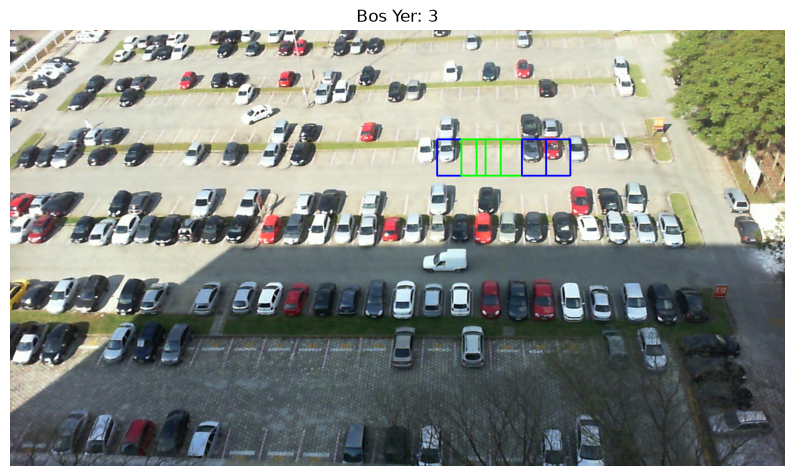

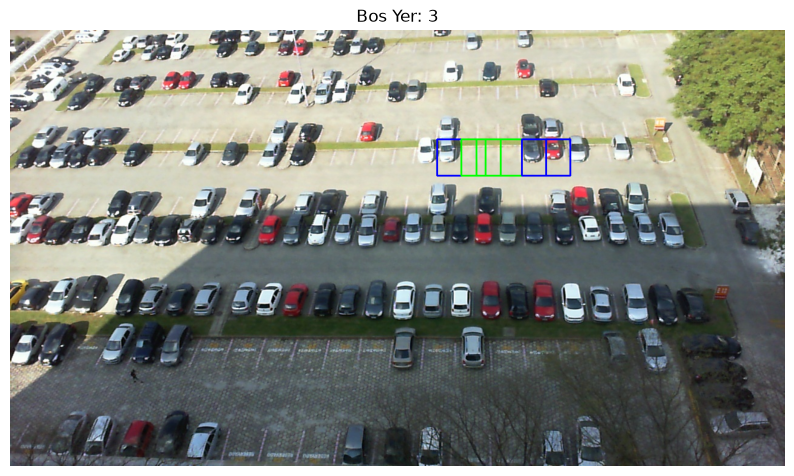

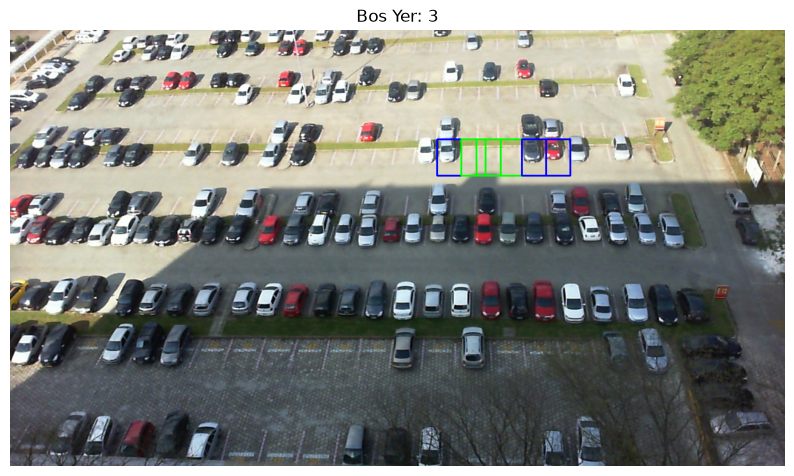

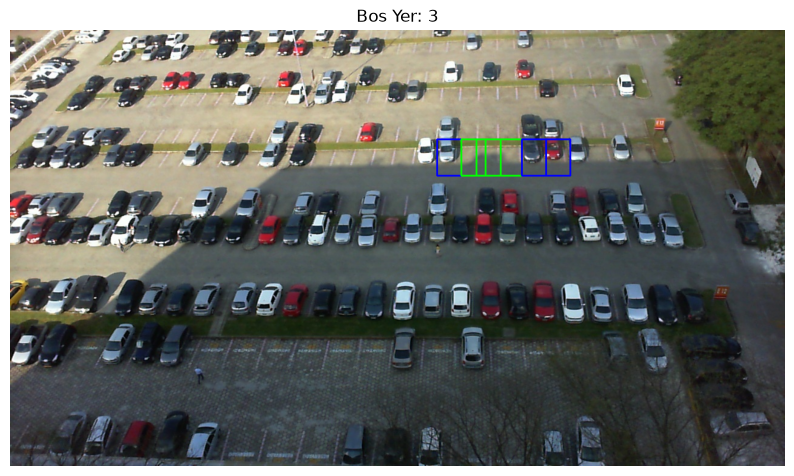

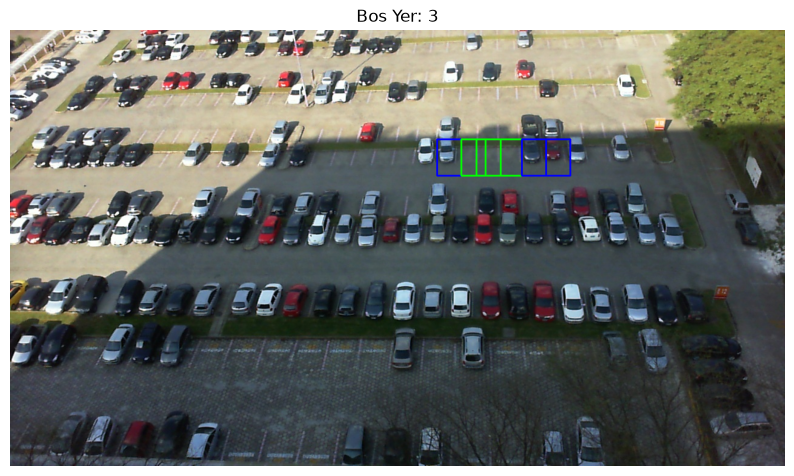

In [40]:
import cv2
import numpy as np
import glob
import matplotlib.pyplot as plt

park_yerleri = [
    {"id": 1, "koordinat": (705, 180, 745, 240)},
    {"id": 2, "koordinat": (745, 180, 785, 240)},
    {"id": 3, "koordinat": (770, 180, 810, 240)},
    {"id": 4, "koordinat": (810, 180, 845, 240)},
    {"id": 5, "koordinat": (845, 180, 885, 240)},
    {"id": 6, "koordinat": (885, 180, 925, 240)}
]

kernel = np.ones((3, 3), np.uint8)
resim_yollari = glob.glob("../data/gelistirme/*.jpg")
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))

for resim_yolu in resim_yollari[:5]:
    resim = cv2.imread(resim_yolu)
    
    if resim is None:
        continue
        
    cizim_resmi = resim.copy()
    gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
    esitlenmis_gri = clahe.apply(gri)
    blur = cv2.GaussianBlur(esitlenmis_gri, (5, 5), 0)
    
    # YENİ ADIM: Canny yerine Sobel kullanarak sadece X eksenindeki (Dikey) kenarları buluyoruz.
    # 1, 0 parametreleri X'i açıp Y'yi kapatır. Böylece yatay gölge çizgisi görünmez olur.
    sobel_x = cv2.Sobel(blur, cv2.CV_8U, 1, 0, ksize=3)
    
    # Sobel'den gelen gri tonlu kenarları Canny gibi keskin siyah-beyaza (Binary) çeviriyoruz
    _, sobel_binary = cv2.threshold(sobel_x, 50, 255, cv2.THRESH_BINARY)
    
    # Morfolojiyi bu yeni dikey kenarların üzerine uyguluyoruz
    morfoloji = cv2.dilate(sobel_binary, kernel, iterations=1)
    
    bos_park_sayisi = 0
    
    for park in park_yerleri:
        x1, y1, x2, y2 = park["koordinat"]
        roi = morfoloji[y1:y2, x1:x2]
        
        beyaz_piksel = cv2.countNonZero(roi)
        toplam_piksel = roi.shape[0] * roi.shape[1]
        yuzde = (beyaz_piksel / toplam_piksel) * 100
        
        # Eşik değerimizi tekrar %8 olarak test ediyoruz
        if yuzde > 12.0:
            cv2.rectangle(cizim_resmi, (x1, y1), (x2, y2), (255, 0, 0), 2)
        else:
            cv2.rectangle(cizim_resmi, (x1, y1), (x2, y2), (0, 255, 0), 2)
            bos_park_sayisi += 1
            
    cizim_resmi_rgb = cv2.cvtColor(cizim_resmi, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(10, 6))
    plt.imshow(cizim_resmi_rgb)
    plt.title(f"Bos Yer: {bos_park_sayisi}")
    plt.axis('off')
    plt.show()

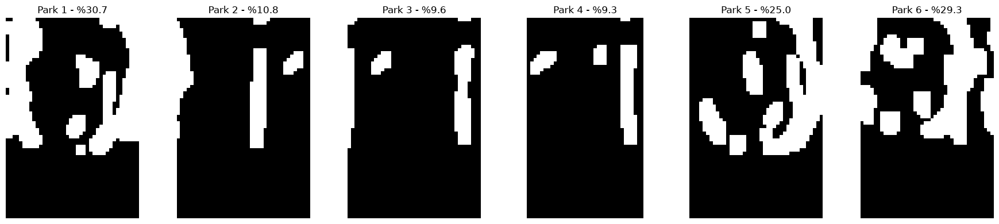

In [38]:
# Sadece gölgenin sorun yarattığı 2. fotoğrafı (indeks 1) mercek altına alıyoruz
resim_yolu = resim_yollari[1] 
resim = cv2.imread(resim_yolu)

gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
esitlenmis_gri = clahe.apply(gri)
blur = cv2.GaussianBlur(esitlenmis_gri, (5, 5), 0)

# Sobel ile dikey kenarları arıyoruz
sobel_x = cv2.Sobel(blur, cv2.CV_8U, 1, 0, ksize=3)
_, sobel_binary = cv2.threshold(sobel_x, 50, 255, cv2.THRESH_BINARY)
morfoloji = cv2.dilate(sobel_binary, kernel, iterations=1)

plt.figure(figsize=(18, 4))
for i, park in enumerate(park_yerleri):
    x1, y1, x2, y2 = park["koordinat"]
    roi = morfoloji[y1:y2, x1:x2]
    
    beyaz_piksel = cv2.countNonZero(roi)
    toplam_piksel = roi.shape[0] * roi.shape[1]
    yuzde = (beyaz_piksel / toplam_piksel) * 100
    
    plt.subplot(1, 6, i+1)
    plt.imshow(roi, cmap='gray')
    plt.title(f"Park {park['id']} - %{yuzde:.1f}")
    plt.axis('off')

plt.tight_layout()
plt.show()

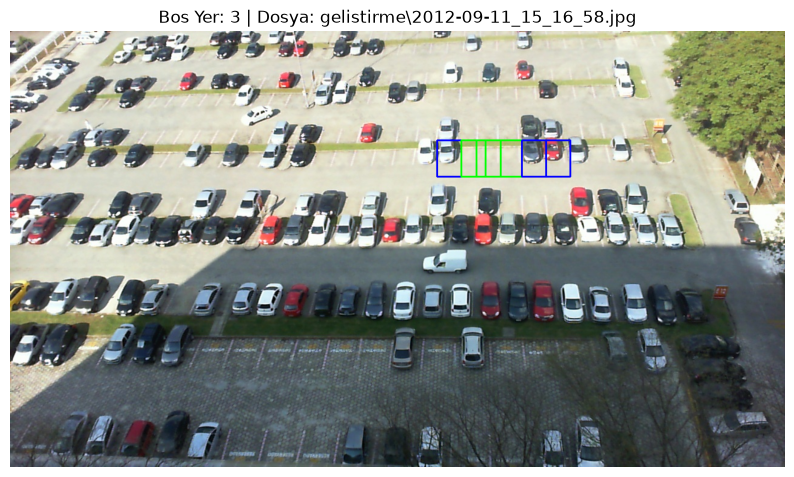

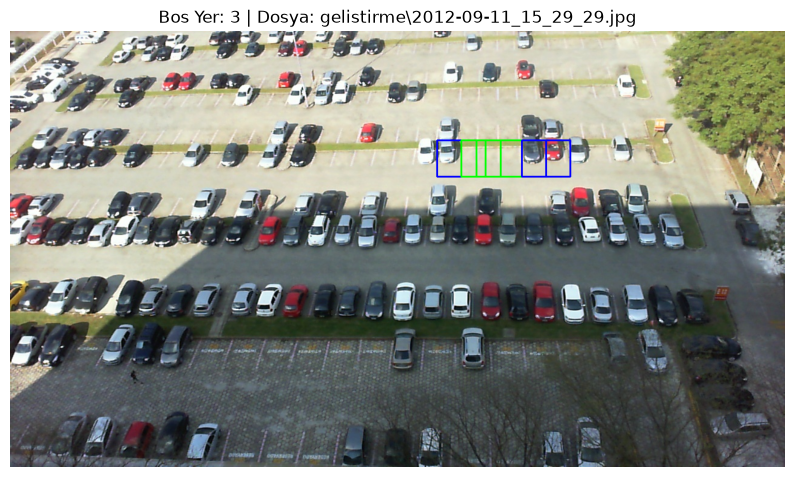

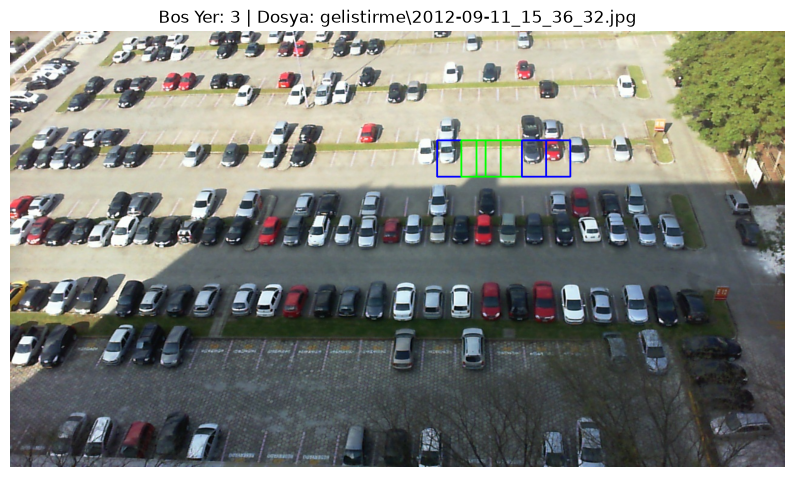

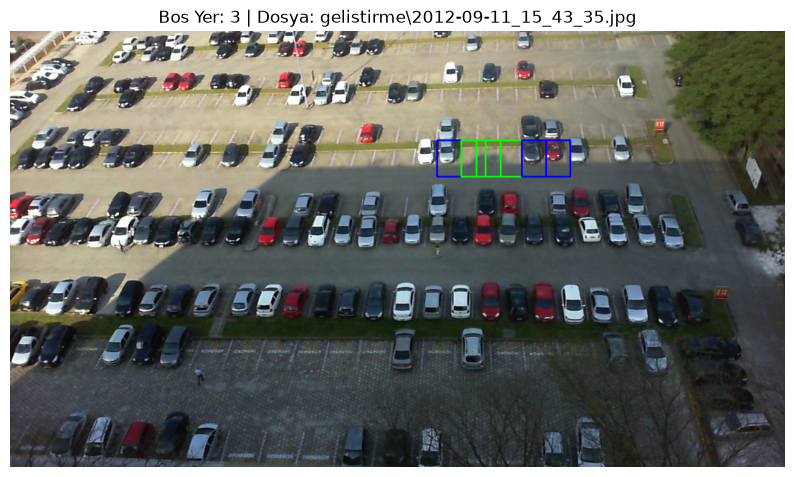

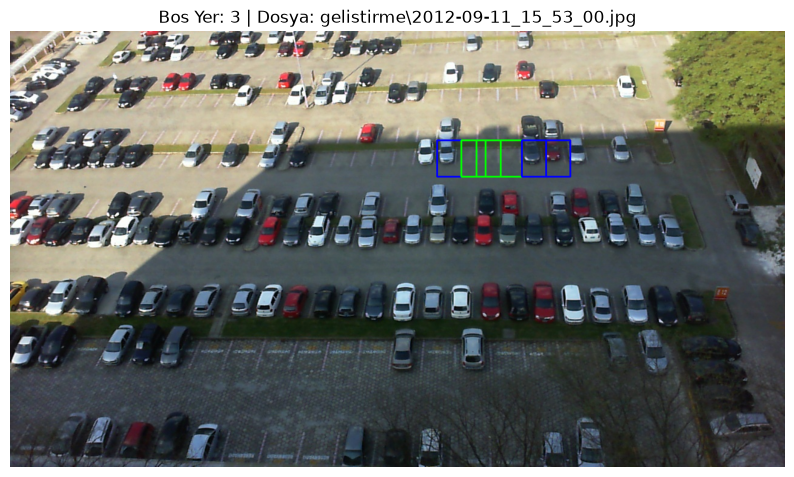

...

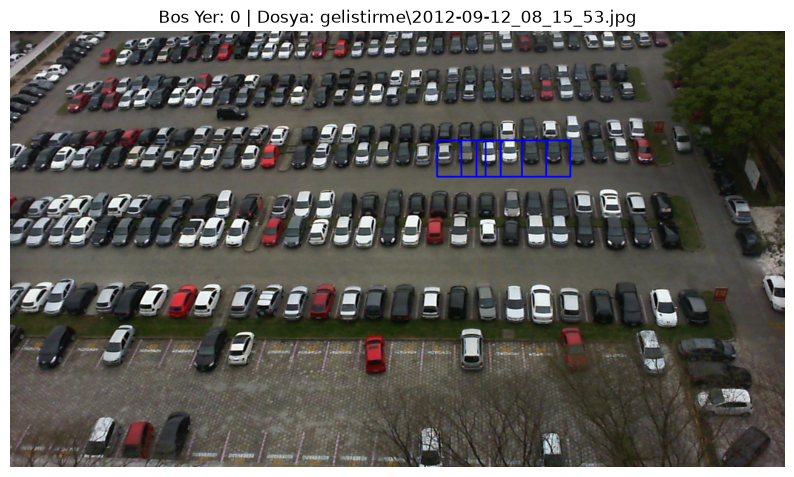

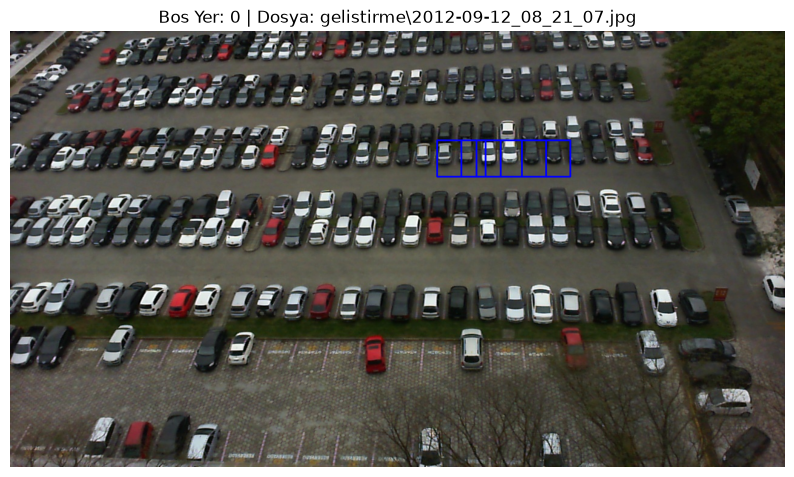

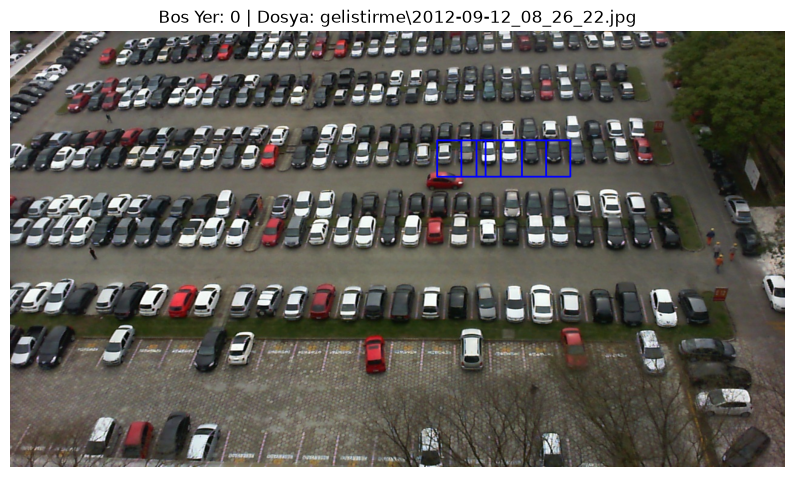

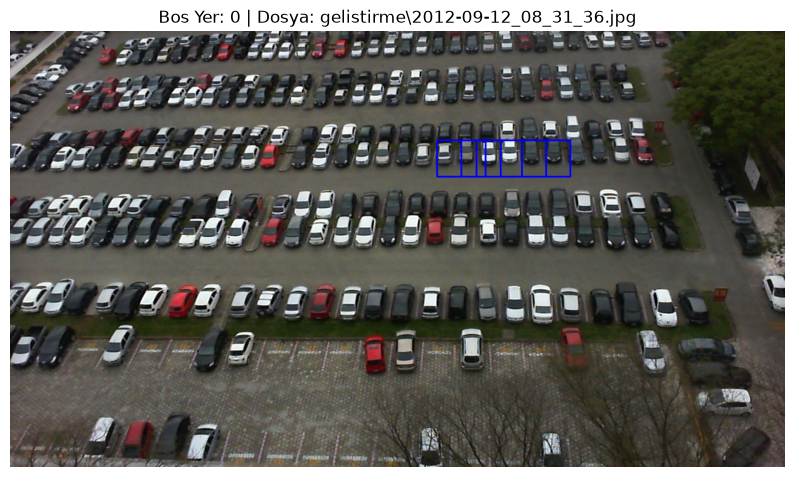

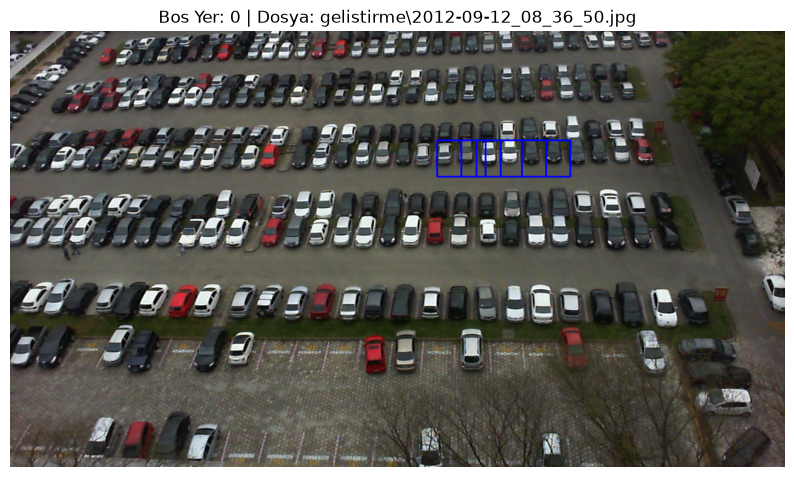

In [41]:
import cv2
import numpy as np
import glob
import matplotlib.pyplot as plt

park_yerleri = [
    {"id": 1, "koordinat": (705, 180, 745, 240)},
    {"id": 2, "koordinat": (745, 180, 785, 240)},
    {"id": 3, "koordinat": (770, 180, 810, 240)},
    {"id": 4, "koordinat": (810, 180, 845, 240)},
    {"id": 5, "koordinat": (845, 180, 885, 240)},
    {"id": 6, "koordinat": (885, 180, 925, 240)}
]

kernel = np.ones((3, 3), np.uint8)
resim_yollari = glob.glob("../data/gelistirme/*.jpg")
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))

# [:5] kısıtlamasını sildik, klasördeki 42 fotoğrafın TAMAMI işlenecek
for resim_yolu in resim_yollari:
    resim = cv2.imread(resim_yolu)
    
    if resim is None:
        continue
        
    cizim_resmi = resim.copy()
    gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
    esitlenmis_gri = clahe.apply(gri)
    blur = cv2.GaussianBlur(esitlenmis_gri, (5, 5), 0)
    
    sobel_x = cv2.Sobel(blur, cv2.CV_8U, 1, 0, ksize=3)
    _, sobel_binary = cv2.threshold(sobel_x, 50, 255, cv2.THRESH_BINARY)
    morfoloji = cv2.dilate(sobel_binary, kernel, iterations=1)
    
    bos_park_sayisi = 0
    
    for park in park_yerleri:
        x1, y1, x2, y2 = park["koordinat"]
        roi = morfoloji[y1:y2, x1:x2]
        
        beyaz_piksel = cv2.countNonZero(roi)
        toplam_piksel = roi.shape[0] * roi.shape[1]
        yuzde = (beyaz_piksel / toplam_piksel) * 100
        
        # SENİN BULDUĞUN OPTİMUM EŞİK DEĞERİ: %12.0
        if yuzde > 12.0:
            cv2.rectangle(cizim_resmi, (x1, y1), (x2, y2), (255, 0, 0), 2)
        else:
            cv2.rectangle(cizim_resmi, (x1, y1), (x2, y2), (0, 255, 0), 2)
            bos_park_sayisi += 1
            
    cizim_resmi_rgb = cv2.cvtColor(cizim_resmi, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(10, 6))
    plt.imshow(cizim_resmi_rgb)
    plt.title(f"Bos Yer: {bos_park_sayisi} | Dosya: {resim_yolu.split('/')[-1]}")
    plt.axis('off')
    plt.show()